# Étude de cas Road Crash — Reproduction commentée du code de Rakesh Nain
## PySpark : RDD, DataFrame et Spark SQL — données 2012–2019

**Auteur du rendu :** Alex Abdallah • **Formation / groupe :** Fise 5A

Ce rendu suit **les cellules de code de l'auteur, leurs noms de variables et leur ordre**. Les explications en français, les vérifications, les visualisations supplémentaires et les corrections sont ajoutées dans des cellules distinctes. Les cellules de l'auteur sont conservées textuellement ; l'exemple `bank.csv`, sans rapport avec les données du sujet, est présenté sans être exécuté.

**Référence :** Rakesh Nain, [article Medium, 2021](https://medium.com/rakesh-nain/big-data-analysis-of-road-crash-data-using-pyspark-with-pyspark-tutorial-c78ff2c35588). Code et données historiques : [dépôt GitHub de l'auteur](https://github.com/RakeshNain/Big-data-Analysis-of-Road-Crash-Data-using-PySpark-with-PySpark-Tutorial), commit `dab8e6466747903bf1e5bd21ce63fea31bfb6dcc`. Producteur des données : gouvernement d'Australie-Méridionale, [Data.SA](https://data.sa.gov.au/). Le fichier de métadonnées accompagne le dépôt.

**Convention de lecture :** « Code de l'auteur » = reproduction ; « Ajout » = explication, contrôle ou extension ; « Correction complémentaire » = version qui résout un problème identifié, sans supprimer le code reproduit.

**Environnement conseillé :** Python 3.10–3.12, Java 17, PySpark 3.5.6. Ouvrir dans Jupyter ou Google Colab et exécuter du haut vers le bas. Internet est nécessaire au premier téléchargement.

## 1. Objectifs et notions essentielles

L'étude examine les accidents routiers et les unités impliquées. Une **unité** peut être un véhicule, un piéton, un animal ou un obstacle. Une **victime** est une personne blessée ou décédée ; les décès en constituent un sous-ensemble.

- Un **RDD** est une collection partitionnée sur laquelle on applique notamment `map`, `filter` et des jointures.
- Un **DataFrame** organise les données en colonnes et bénéficie du moteur d'optimisation de Spark.
- **Spark SQL** interroge ces tables en SQL avec le même moteur.

Les transformations décrivent un calcul ; les actions (`count`, `collect`, `show`) déclenchent son exécution. C'est l'évaluation paresseuse. Le mode `local[*]` de l'auteur utilise les cœurs d'une seule machine : il ne s'agit pas ici d'une exécution sur plusieurs serveurs.

### Ajout — Préparation de l'environnement

La cellule suivante installe seulement les bibliothèques absentes. En cas de changement de version dans un notebook déjà ouvert, redémarrer le noyau avant de reprendre. Java doit être installé séparément sur une machine locale.

In [32]:
import importlib.util
import subprocess
import sys

requirements = {
    "pyspark": "pyspark==3.5.6",
    "pandas": "pandas==2.2.3",
    "matplotlib": "matplotlib==3.9.4",
}
missing = [package for module, package in requirements.items()
           if importlib.util.find_spec(module) is None]
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", *missing])
subprocess.run(["java", "-version"], check=True)
print("Python :", sys.version.split()[0])

Python : 3.13.5


### Ajout — Télécharger les données sans changer les chemins de l'auteur

Les dossiers `crash_data/` et `units_data/` sont placés à côté du notebook, afin que les lignes `./crash_data/*.csv` et `./units_data/*.csv` restent inchangées. Les fichiers déjà présents sont vérifiés ; ils ne sont pas écrasés. L'instantané du dépôt et les empreintes SHA-256 permettent de retracer les entrées.

In [33]:
import os
import sys
import json
import csv
import hashlib
import shutil
import subprocess
from pathlib import Path
from datetime import datetime, timezone
from IPython.display import display, Markdown

REPO_URL = "https://github.com/RakeshNain/Big-data-Analysis-of-Road-Crash-Data-using-PySpark-with-PySpark-Tutorial.git"
SOURCE_COMMIT = "dab8e6466747903bf1e5bd21ce63fea31bfb6dcc"
DATA_ROOT = Path("source_originale")
OUT = Path("resultats_road_crash")
OUT.mkdir(exist_ok=True)
if not DATA_ROOT.exists():
    subprocess.run(["git", "clone", REPO_URL, str(DATA_ROOT)], check=True)
    subprocess.run(["git", "-C", str(DATA_ROOT), "checkout", "--detach", SOURCE_COMMIT], check=True)
if (DATA_ROOT / ".git").exists():
    source_revision = subprocess.check_output(["git", "-C", str(DATA_ROOT), "rev-parse", "HEAD"], text=True).strip()
    assert source_revision == SOURCE_COMMIT, "Utiliser un dossier source au commit indiqué."
else:
    source_revision = "archive sans métadonnées Git"

manifest = []
for folder in ["crash_data", "units_data"]:
    source_folder, destination = DATA_ROOT / folder, Path(folder)
    if not destination.exists():
        shutil.copytree(source_folder, destination)
    paths = sorted(destination.glob("*.csv"))
    assert len(paths) == 8, f"Huit CSV attendus dans {folder}."
    for path in paths:
        sha = hashlib.sha256(path.read_bytes()).hexdigest()
        assert sha == hashlib.sha256((source_folder / path.name).read_bytes()).hexdigest(), f"Fichier différent : {path}"
        manifest.append({"fichier": str(path), "octets": path.stat().st_size, "sha256": sha})
os.environ["PYSPARK_PYTHON"] = sys.executable
# Rendu lisible des listes collectées ; ne limite pas la quantité rapatriée par collect().
try:
    get_ipython().display_formatter.formatters['text/plain'].max_seq_length = 12
except NameError:
    pass
print("Révision source :", source_revision)
print("Fichiers CSV vérifiés :", len(manifest))

Révision source : dab8e6466747903bf1e5bd21ce63fea31bfb6dcc
Fichiers CSV vérifiés : 16


### Code de l'auteur — Imports

On conserve les imports du sujet, y compris certains peu utilisés. `F` regroupe les fonctions SQL, et `udf` permet d'exécuter une fonction Python dans une colonne Spark. Pour un calcul simple, une expression Spark native est généralement préférable ; les UDF sont ici conservées pour suivre le tutoriel.

In [34]:
from pyspark import SparkConf
from pyspark import SparkContext
from pyspark.sql import SparkSession
from pyspark.sql.functions import udf
from pyspark.sql.types import IntegerType
from pyspark.sql.types import LongType
from pyspark.sql.types import FloatType
from pyspark.rdd import RDD
from pyspark.sql.types import StringType
from pyspark.sql.functions import col
import pyspark.sql.functions as F
import csv
from datetime import datetime
from functools import reduce
import pandas as pd
import matplotlib.pyplot as plt

### Code de l'auteur — Configuration

`local[*]` autorise l'utilisation de tous les cœurs logiques disponibles. Sur une machine avec peu de mémoire, on peut choisir `local[2]`, mais la cellule reproduite ci-dessous garde le réglage d'origine.

In [35]:
# local[*]: run Spark in local-mode(parallel computing) with as many working processors as logical cores on your machine
# If we want Spark to run locally with 'k' worker threads, we can specify as "local[k]".
master = "local[*]"

# The `appName` field is a name to be shown on the Spark cluster UI page
app_name = "Big data Analysis of Road Crash Data"

# Setup configuration parameters for Spark
spark_conf = SparkConf().setMaster(master).setAppName(app_name)

### Ajout — Réglages pratiques pour un notebook local

On garde le `master` de l'auteur. Les échanges SQL utilisent huit partitions et les RDD ont un parallélisme par défaut de quatre, afin de limiter les petites tâches. L'adresse locale évite les problèmes de résolution du nom de la machine. Ces réglages concernent cette exécution locale.

In [36]:
spark_conf = (spark_conf
    .set("spark.driver.host", "127.0.0.1")
    .set("spark.driver.bindAddress", "127.0.0.1")
    .set("spark.sql.shuffle.partitions", "8")
    .set("spark.default.parallelism", "4"))

### Code de l'auteur — Création de la session Spark

`SparkSession` est le point d'entrée pour les DataFrames et SQL. `SparkContext` fournit les opérations RDD.

In [37]:
# creating a SparkContext object 
spark = SparkSession.builder.config(conf=spark_conf).getOrCreate()
sc = spark.sparkContext
sc.setLogLevel('ERROR')

In [38]:
print("Version Spark :", spark.version)
print("Master :", sc.master)
print("Parallélisme par défaut :", sc.defaultParallelism)
plt.rcParams.update({"figure.dpi": 120, "axes.spines.top": False, "axes.spines.right": False})

Version Spark : 3.5.6
Master : local[*]
Parallélisme par défaut : 4


## 2. Analyse avec les RDD
### 2.1 Code de l'auteur — Créer un RDD depuis une liste

`parallelize` distribue une collection Python. Le second paramètre fixe le nombre de partitions. `collect()` est sans difficulté pour cette liste de dix éléments ; sur une grande table, il rapatrierait toutes les lignes dans la mémoire du pilote.

In [39]:
## FROM A LIST
# By default the number of partitions will be the number of threads
data_list = [i for i in range(10)]
#print(data_list)
rdd = sc.parallelize(data_list)
# You can verify the number of partitions of the data 
print('Default partitions: ',rdd.getNumPartitions())
# the function parallelize can have a second argument to indicate manually how many
# partitions for the data
rdd = sc.parallelize(data_list,5)
# Verify the new number of partitions of the data 
print('Manual partitions: ',rdd.getNumPartitions())
# Show the data by performing the action *collect*
rdd.collect()

Default partitions:  4
Manual partitions:  5


[0, 1, 2, 3, 4, 5, 6, 7, 8, 9]

### 2.2 Code de l'auteur — Charger les CSV

`textFile` produit une chaîne par ligne physique. Le caractère `*` permet de lire les huit fichiers annuels d'un dossier.

In [40]:
# Importing all the "Units" csv files from downloaded 2012–2019 South Australia Road Crash Data into a single RDD.
# creating RDD object by reading csv file
units_rdd = sc.textFile('./units_data/*.csv')

# Importing all the "Crashes" csv files from 2012–2019 into a single RDD.
# creating RDD object by reading csv file
crash_rdd = sc.textFile('./crash_data/*.csv')

### 2.3 Code de l'auteur — Retirer les en-têtes et découvrir les lignes

Les en-têtes sont présents dans chaque fichier annuel. Le filtre retire toutes les lignes égales à l'en-tête lu au début. Le contrôle complémentaire ci-dessous vérifiera que les fichiers partagent bien un même en-tête.

In [ ]:
# Removing the header of units_rdd
units_header = units_rdd.first()
units_rdd = units_rdd.filter(lambda row: row != units_header)   #filter out header
print("Total count of units_rdd: ", units_rdd.count())
print(units_rdd.take(10))

Dossier recherché : C:\Users\Alex\Downloads\units_data
Nombre de CSV trouvés : 8

ERREUR DÉTAILLÉE :

java.lang.UnsatisfiedLinkError: 'boolean org.apache.hadoop.io.nativeio.NativeIO$Windows.access0(java.lang.String, int)'


In [ ]:
# Removing the header of crash_rdd
crash_header = crash_rdd.first()
crash_rdd = crash_rdd.filter(lambda row: row != crash_header)   #filter out header
print("Total count of crash_rdd: ", crash_rdd.count())
print(crash_rdd.take(10))

### Ajout — Contrôler les CSV avant d'interpréter les positions

L'auteur utilise ensuite `split(',')`. Cette méthode ne gère pas les virgules à l'intérieur de champs entre guillemets. On la conserve pour reproduire l'étude, mais on mesure ses divergences avec un véritable parseur CSV. Les corrections complémentaires emploieront le lecteur CSV Spark ou `csv.reader`.

In [ ]:
def csv_header(path):
    with path.open(encoding="utf-8-sig", newline="") as stream:
        return next(csv.reader(stream))

for folder in ["crash_data", "units_data"]:
    files = sorted(Path(folder).glob("*.csv"))
    header = csv_header(files[0])
    for path in files:
        assert csv_header(path) == header, f"En-tête différent : {path}"

def split_differs(line):
    naive = [x.replace('"', '') for x in line.split(',')]
    parsed = next(csv.reader([line]))
    return naive != parsed

print("Lignes unités où split(',') diffère du parseur CSV :", units_rdd.filter(split_differs).count())
print("Lignes accidents où split(',') diffère du parseur CSV :", crash_rdd.filter(split_differs).count())
print("En-têtes annuels : cohérents")
print("Colonnes des unités :", csv_header(sorted(Path("units_data").glob("*.csv"))[0]))

Lignes unités où split(',') diffère du parseur CSV : 0
Lignes accidents où split(',') diffère du parseur CSV : 21379
En-têtes annuels : cohérents
Colonnes des unités : ['REPORT_ID', 'Unit No', 'No Of Cas', 'Veh Reg State', 'Unit Type', 'Veh Year', 'Direction Of Travel', 'Sex', 'Age', 'Lic State', 'Licence Class', 'Licence Type', 'Towing', 'Unit Movement', 'Number Occupants', 'Postcode', 'Rollover', 'Fire']


### 2.4 Code de l'auteur — Examiner les partitions

Le découpage initial dépend des fichiers, de leurs blocs et de la configuration. Il ne garantit pas une répartition aléatoire ni des partitions de taille identique.

In [ ]:
print("Units Data:")
print(f"Total partitions: {units_rdd.getNumPartitions()}")
print("Crash Data:")
print(f"Total partitions: {crash_rdd.getNumPartitions()}")

Units Data:
Total partitions: 8
Crash Data:
Total partitions: 8


### 2.5 Code de l'auteur — Partitionner selon l'immatriculation

La position `3` correspond à **`Veh Reg State`**, l'État d'immatriculation, et non à `Lic State`, qui indique l'État de délivrance du permis. Le code de l'auteur utilise bien la position de l'immatriculation ; c'est son explication qu'il faut préciser.

Le premier RDD contient des couples `(État, autres colonnes)`. La fonction de partitionnement envoie SA dans la partition 0 et toutes les autres valeurs, y compris vides, dans la partition 1.

In [ ]:
# define a function which will be applied to each rdd element
def parseRecord(line):
    lines = line.split(',')
    array_line = []
    for value in lines:
        array_line.append(str(value).replace('"', ''))
    return (array_line[3], [x for i,x in enumerate(array_line) if i!=3] )
units_state_rdd = units_rdd.map(parseRecord)

In [ ]:
# define function to partition data into two parts, one only for SA state and other one for alll the states
def hash_SA(key):
    if key == 'SA':
        return 0
    else:
        return 1
    
SA_partitioned_rdd = units_state_rdd.partitionBy(2, hash_SA)

### Code de l'auteur — Compter les éléments de chaque partition

La fonction est reproduite. Son `glom().collect()` transfère néanmoins toutes les données sur le pilote. C'est acceptable pour reproduire ce petit jeu historique, mais une alternative plus économe est ajoutée ensuite.

In [ ]:
#A Function to print the number of elements in each partion of the given rdd
def print_partitions(data):
    if isinstance(data, RDD):
        numPartitions = data.getNumPartitions()
        partitions = data.glom().collect()
    else:
        numPartitions = data.rdd.getNumPartitions()
        partitions = data.rdd.glom().collect()
    
    print(f"NUMBER OF PARTITIONS: {numPartitions}")
    for index, partition in enumerate(partitions):
        if len(partition) > 0:
            print(f"Partition {index}: {len(partition)} records")
print_partitions(SA_partitioned_rdd)

NUMBER OF PARTITIONS: 2
Partition 0: 218366 records
Partition 1: 54225 records


In [ ]:
# Ajout : seules les tailles des partitions sont rapatriées.
partition_sizes = sorted(SA_partitioned_rdd.mapPartitionsWithIndex(
    lambda index, records: [(index, sum(1 for _ in records))]).collect())
display(pd.DataFrame(partition_sizes, columns=["partition", "unites"]))
assert sum(size for _, size in partition_sizes) == units_rdd.count()

,partition,unites
0,0,218366
1,1,54225


**Interprétation :** une forte concentration sur SA est cohérente avec le périmètre géographique. Le déséquilibre entre les deux partitions illustre le *data skew* ; ce choix sert à comprendre le mécanisme, sans garantir de meilleures performances.

### 2.6 Code de l'auteur — Âge moyen selon le sexe renseigné

La fonction écarte les âges vides ou codés `XXX` et les sexes `Unknown`. `groupByKey` réunit les âges par catégorie, puis `mapValues` calcule leur moyenne. Les valeurs concernent les contrôleurs d'unités enregistrés dans les accidents, pas la population générale.

In [ ]:
# define a function that will be applied to each rdd element, apply filter on it and returns only gender and age only
def parseGenderAge(line):
    lines = line.split(',')
    array_line = []
    for value in lines:
        array_line.append(str(value).replace('"', ''))
    if (array_line[8] != 'XXX') & (array_line[8] != '') & (array_line[7] != 'Unknown'):
        return (array_line[7], int(array_line[8]))
gender_age_rdd = units_rdd.map(parseGenderAge)
filtered_gender_age_rdd=gender_age_rdd.filter(lambda x: x is not None).filter(lambda x: x != "")
gender_age_avg_rdd= filtered_gender_age_rdd.groupByKey().mapValues(lambda x: round(sum(x) / len(x),2))
gender_age_avg_rdd.collect()

Out[18]: [('Male', 40.8), ('Female', 40.08)]


In [ ]:
# Ajout : vérifier une agrégation plus économe avec sommes et effectifs.
age_control = (filtered_gender_age_rdd.mapValues(lambda age: (age, 1))
    .reduceByKey(lambda a, b: (a[0] + b[0], a[1] + b[1]))
    .map(lambda kv: (kv[0], kv[1][1], round(kv[1][0] / kv[1][1], 2))))
age_control_pd = pd.DataFrame(age_control.collect(), columns=["sexe", "effectif", "age_moyen"])
display(age_control_pd.sort_values("sexe"))
assert dict(gender_age_avg_rdd.collect()) == dict(age_control_pd[["sexe", "age_moyen"]].itertuples(index=False, name=None))

,sexe,effectif,age_moyen
1,Female,85603,40.08
0,Male,131892,40.80


**Interprétation :** les moyennes observées sont proches. Cela ne signifie pas que les distributions d'âge sont identiques, ni que le sexe explique le risque d'accident. `reduceByKey` permet de calculer cette moyenne à partir de sommes et d'effectifs, sans conserver tous les âges par clé.

### 2.7 Code de l'auteur — Années de fabrication extrêmes

Les années `XXXX` et vides sont écartées. Une valeur telle que 1900 est une valeur observée à investiguer ; on ne conclut pas automatiquement à l'existence d'un véhicule historique. Le code trie et collecte le résultat complet avant de garder cinq lignes : pour de plus grands volumes, `takeOrdered(5)` serait préférable.

In [ ]:
# define a function that will be applied to each rdd element, apply filter on it and
# returns only Registration State, Year and Unit type only
def parseYear(line):
    lines = line.split(',')
    array_line = []
    for value in lines:
        array_line.append(str(value).replace('"', ''))
    if (array_line[5] != 'XXXX') & (array_line[5] != ''):
        return int(array_line[5]), [array_line[3], array_line[4]]
year_rdd = units_rdd.map(parseYear)
clean_year_rdd=year_rdd.filter(lambda x: x is not None).filter(lambda x: x != "")
print("Oldest year 5 crashes:\n", clean_year_rdd.sortByKey(ascending=True).collect()[0:5])
print("\n")
print("Newest year 5 crashes:\n", clean_year_rdd.sortByKey(ascending=False).collect()[0:5])

Oldest year 5 crashes:
 [(1900, ['VIC', 'Motor Cycle']), (1900, ['SA', 'Motor Cycle']), (1900, ['SA', 'Motor Cycle']), (1900, ['SA', 'Motor Cycle']), (1900, ['SA', 'Motor Cycle'])]


Newest year 5 crashes:
 [(2019, ['SA', 'Station Wagon']), (2019, ['SA', 'OMNIBUS']), (2019, ['SA', 'Motor Cars - Sedan']), (2019, ['SA', 'Station Wagon']), (2019, ['SA', 'SEMI TRAILER'])]


## 3. Analyse avec les DataFrames
### 3.1 Code de l'auteur — Créer un exemple de DataFrame

Le schéma décrit les noms, les types et la possibilité de valeurs nulles. Cet exemple sert uniquement à comprendre l'API.

In [ ]:
df = spark.createDataFrame([(1,'Aaditya','A'),(2,'Chinnavit','C'),(3,'Neha','N'),(4,'Huashun','H'),(5,'Mohammad','M'),
                            (10,'Prajwol', 'P'),(1,'Paras','P'),(1, 'Tooba','T'),(3, 'David','D'),(4,'Cheng','C'),(9,'Haqqani','H')],
                           ['Id','Name','Initial'])
#display the rows of the dataframe
df.show(5)
#view the schema
df.printSchema()

+---+---------+-------+
| Id|     Name|Initial|
+---+---------+-------+
|  1|  Aaditya|      A|
|  2|Chinnavit|      C|
|  3|     Neha|      N|
|  4|  Huashun|      H|
|  5| Mohammad|      M|
+---+---------+-------+
only showing top 5 rows

root
 |-- Id: long (nullable = true)
 |-- Name: string (nullable = true)
 |-- Initial: string (nullable = true)



### Exemple de l'auteur non exécuté — `bank.csv`

```python
df = spark.read.csv("bank.csv",header=True)
```

Cette ligne illustre une autre méthode de lecture. **`bank.csv` ne fait pas partie des données Road Crash** : l'exécuter tel quel provoquerait une erreur de fichier absent. On conserve donc l'exemple ici sans créer de données artificielles.

### 3.2 Code de l'auteur — Lire les tables réelles

Le lecteur CSV tient compte des guillemets. Sans `inferSchema=True`, les colonnes sont initialement des chaînes. Les identifiants et les codes conservent leurs zéros initiaux.

In [ ]:
units_df = spark.read.format('csv')\
            .option('header',True).option('escape','"')\
            .load('./units_data/*.csv')
crash_df = spark.read.format('csv')\
            .option('header',True).option('escape','"')\
            .load('./crash_data/*.csv')

### Ajout — Examiner le schéma et la qualité

On conserve les noms de colonnes de l'auteur. Une table séparée permettra de mesurer les manquants sans imputation et de vérifier la granularité : une ligne par accident, une ligne par unité impliquée.

In [ ]:
crash_df.printSchema()
units_df.printSchema()
n_crash, n_units = crash_df.count(), units_df.count()
assert n_crash == crash_rdd.count() and n_units == units_rdd.count()
assert crash_df.filter(col("REPORT_ID").isNull()).count() == 0
assert units_df.filter(col("REPORT_ID").isNull() | col("Unit No").isNull()).count() == 0
assert crash_df.groupBy("REPORT_ID").count().filter("count > 1").count() == 0
assert units_df.groupBy("REPORT_ID", "Unit No").count().filter("count > 1").count() == 0
assert units_df.join(crash_df.select("REPORT_ID"), "REPORT_ID", "left_anti").count() == 0

def missing_summary(frame, label):
    counts = frame.agg(*[F.sum((col(c).isNull() | (F.trim(col(c)) == "")).cast("int")).alias(c)
                         for c in frame.columns]).first().asDict()
    n = frame.count()
    return pd.DataFrame([{"table": label, "colonne": c, "manquants": value,
                          "part_manquants_pct": 100 * value / n} for c, value in counts.items()])
quality_pd = pd.concat([missing_summary(crash_df, "accidents"), missing_summary(units_df, "unites")], ignore_index=True)
display(quality_pd.sort_values("part_manquants_pct", ascending=False).round(2))
print("Clés, relations et effectifs RDD/DataFrame : vérifiés")
print("Les codes Unknown, XXX, XXXX et XX restent présents dans les tables de l'auteur.")

root
 |-- REPORT_ID: string (nullable = true)
 |-- Stats Area: string (nullable = true)
 |-- Suburb: string (nullable = true)
 |-- Postcode: string (nullable = true)
 |-- LGA Name: string (nullable = true)
 |-- Total Units: string (nullable = true)
 |-- Total Cas: string (nullable = true)
 |-- Total Fats: string (nullable = true)
 |-- Total SI: string (nullable = true)
 |-- Total MI: string (nullable = true)
 |-- Year: string (nullable = true)
 |-- Month: string (nullable = true)
 |-- Day: string (nullable = true)
 |-- Time: string (nullable = true)
 |-- Area Speed: string (nullable = true)
 |-- Position Type: string (nullable = true)
 |-- Horizontal Align: string (nullable = true)
 |-- Vertical Align: string (nullable = true)
 |-- Other Feat: string (nullable = true)
 |-- Road Surface: string (nullable = true)
 |-- Moisture Cond: string (nullable = true)
 |-- Weather Cond: string (nullable = true)
 |-- DayNight: string (nullable = true)
 |-- Crash Type: string (nullable = true)
 |-- U

,table,colonne,manquants,part_manquants_pct
50,unites,Fire,272380,99.92
29,accidents,Drugs Involved,125818,98.55
49,unites,Rollover,265388,97.36
28,accidents,DUI Involved,123693,96.88
43,unites,Licence Class,68441,25.11
42,unites,Lic State,48766,17.89
44,unites,Licence Type,48695,17.86
45,unites,Towing,39164,14.37
36,unites,Veh Reg State,38778,14.23
38,unites,Veh Year,38751,14.22


### 3.3 Code de l'auteur — Accidents à Adelaide avec plus de trois victimes

Le filtre porte exactement sur la localité ADELAIDE, pas sur l'ensemble de l'agglomération. La conversion de `Total Cas` est indispensable pour comparer des nombres.

In [ ]:
# changing the type of column("Total Cas'") to interger type
crash_df = crash_df.withColumn('Total Cas',F.col('Total Cas').cast(IntegerType()))
# applying filter
adelaide_crash_casualty_df = crash_df.filter(col("Total Cas") > 3).filter(col("Suburb") == 'ADELAIDE')
adelaide_crash_casualty_df.collect()

Out[24]: 
[Row(REPORT_ID='2012-4842-21/08/2019', Stats Area='1 City', Suburb='ADELAIDE', Postcode='5000', LGA Name='CITY OF ADELAIDE', Total Units='2', Total Cas=4, Total Fats='0', Total SI='0', Total MI='4', Year='2012', Month='March', Day='Thursday', Time='04:00 pm', Area Speed='050', Position Type='Not Divided', Horizontal Align='Straight road', Vertical Align='Level', Other Feat='Not Applicable', Road Surface='Sealed', Moisture Cond='Dry', Weather Cond='Not Raining', DayNight='Daylight', Crash Type='Rear End', Unit Resp='01', Entity Code='Driver Rider', CSEF Severity='2: MI', Traffic Ctrls='No Control', DUI Involved=None, Drugs Involved=None, ACCLOC_X='1327421.54', ACCLOC_Y='1669848.73', UNIQUE_LOC='13274221669849'),
 Row(REPORT_ID='2012-5769-21/08/2019', Stats Area='1 City', Suburb='ADELAIDE', Postcode='5000', LGA Name='CITY OF ADELAIDE', Total Units='2', Total Cas=4, Total Fats='0', Total SI='0', Total MI='4', Year='2012', Month='March', Day='Friday', Time='09:30 am', Area Speed=

### 3.4 Code de l'auteur — Dix accidents avec le plus de victimes

Un tri décroissant place les plus grands nombres en premier. En cas d'égalité, l'ordre des lignes n'est pas fixé ; des exécutions peuvent afficher des identifiants différents au seuil du top 10.

In [ ]:
crash_df.sort(col('Total Cas'), ascending=False).show(10)

+--------------------+--------------+-------------+--------+--------------------+-----------+---------+----------+--------+--------+----+--------+---------+--------+----------+-------------+--------------------+--------------+--------------+------------+-------------+------------+--------+-----------+---------+------------+-------------+---------------+------------+--------------+----------+----------+--------------+
|           REPORT_ID|    Stats Area|       Suburb|Postcode|            LGA Name|Total Units|Total Cas|Total Fats|Total SI|Total MI|Year|   Month|      Day|    Time|Area Speed|Position Type|    Horizontal Align|Vertical Align|    Other Feat|Road Surface|Moisture Cond|Weather Cond|DayNight| Crash Type|Unit Resp| Entity Code|CSEF Severity|  Traffic Ctrls|DUI Involved|Drugs Involved|  ACCLOC_X|  ACCLOC_Y|    UNIQUE_LOC|
+--------------------+--------------+-------------+--------+--------------------+-----------+---------+----------+--------+--------+----+--------+---------+--

### 3.5 Code de l'auteur — Décès par type d'accident

`sum` calcule ici le nombre de décès, et non le nombre d'accidents mortels. Un accident peut faire plusieurs victimes. Les volumes par type ne sont pas des taux ajustés selon l'exposition au trafic.

In [ ]:
crash_df.groupBy('Crash Type').agg(F.sum('Total Fats').alias('Total fatalities')).sort(col('Total fatalities'), ascending=False).show()

+--------------------+----------------+
|          Crash Type|Total fatalities|
+--------------------+----------------+
|    Hit Fixed Object|           245.0|
|             Head On|           136.0|
|      Hit Pedestrian|           109.0|
|           Roll Over|            93.0|
|         Right Angle|            82.0|
|            Rear End|            33.0|
|          Side Swipe|            30.0|
|          Right Turn|            26.0|
|  Hit Parked Vehicle|            10.0|
|          Hit Animal|             7.0|
|               Other|             5.0|
|Left Road - Out o...|             3.0|
|  Hit Object on Road|             2.0|
+--------------------+----------------+



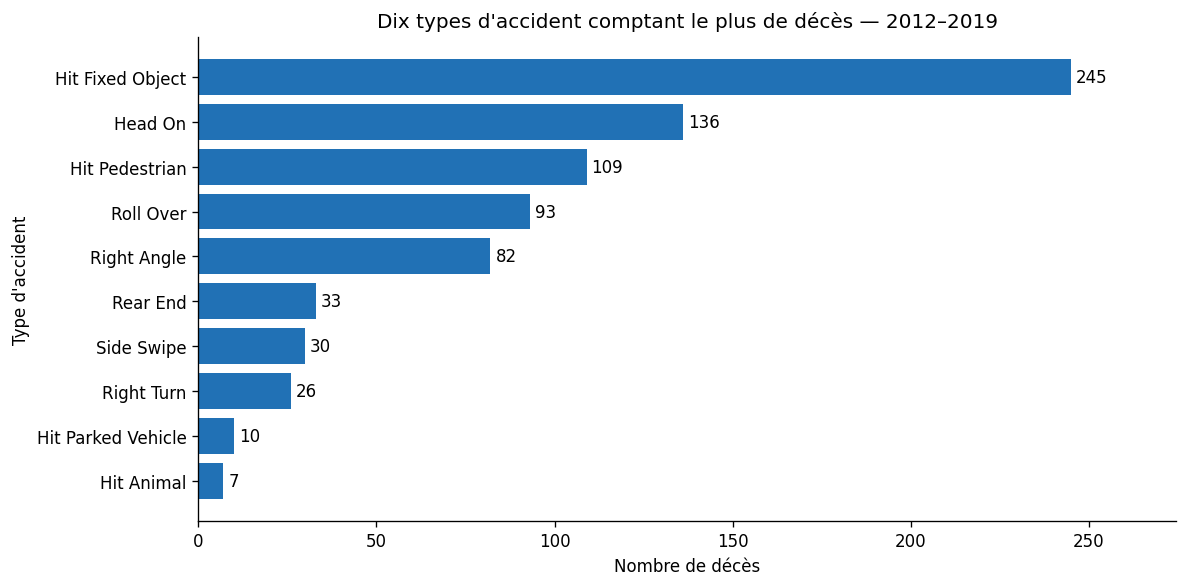

In [ ]:
# Ajout : conserver la table agrégée et tracer les dix premières catégories.
fatalities_by_type = (crash_df.groupBy("Crash Type")
    .agg(F.sum("Total Fats").alias("Total fatalities"))
    .orderBy(F.desc("Total fatalities"), "Crash Type"))
fatalities_type_pd = fatalities_by_type.toPandas()
p = fatalities_type_pd.head(10).sort_values("Total fatalities")
fig, ax = plt.subplots(figsize=(10, 5))
ax.barh(p["Crash Type"], p["Total fatalities"], color="#2171b5")
ax.bar_label(ax.containers[0], padding=3, fmt="%.0f")
ax.set(xlabel="Nombre de décès", ylabel="Type d'accident",
       title="Dix types d'accident comptant le plus de décès — 2012–2019")
ax.margins(x=0.12)
fig.tight_layout()
fig.savefig(OUT / "01_deces_par_type.png", bbox_inches="tight")
plt.show()

### 3.6 Code de l'auteur — Victimes par localité et unité sans permis

La jointure associe chaque accident à ses unités. Le filtre sélectionne `Unlicenced`. **Limite à examiner :** si plusieurs unités sans permis appartiennent au même accident, le total des victimes de l'accident se répète avant la somme. On reproduit d'abord la cellule, puis on ajoute une version qui compte chaque accident une fois.

In [ ]:
# joining both dataframes
complete_df = crash_df.join(units_df,crash_df.REPORT_ID==units_df.REPORT_ID,how='inner')
by_suburb_no_lic_no_df = complete_df.filter(col('Licence Type') == 'Unlicenced').groupby('Suburb').agg(F.sum('Total Cas').alias('Total casualty'))
by_suburb_no_lic_no_df.sort(col('Total casualty'), ascending=False).show()

+---------------+--------------+
|         Suburb|Total casualty|
+---------------+--------------+
|       ADELAIDE|            43|
|      SALISBURY|            30|
|       PROSPECT|            27|
|     INGLE FARM|            22|
| SALISBURY EAST|            20|
|  MORPHETT VALE|            20|
|  MURRAY BRIDGE|            19|
|      DRY CREEK|            19|
|   MAWSON LAKES|            17|
| NORTH ADELAIDE|            17|
|        ENFIELD|            16|
|SALISBURY DOWNS|            15|
|   REGENCY PARK|            15|
|    GEPPS CROSS|            15|
|PARA HILLS WEST|            14|
|         SEATON|            14|
| ELIZABETH PARK|            14|
|   DAVOREN PARK|            13|
|   BEDFORD PARK|            13|
|  MOUNT GAMBIER|            13|
+---------------+--------------+
only showing top 20 rows



### Correction complémentaire — Éviter le surcomptage des victimes

La question retenue est : « Combien de victimes dans les accidents impliquant au moins une unité marquée Unlicenced, pour chaque localité ? » Un `left_semi` conserve un accident s'il existe une unité correspondante sans multiplier ses lignes. Ces victimes ne sont pas nécessairement imputables à l'unité sans permis.

In [ ]:
unlicensed_original = by_suburb_no_lic_no_df
unlicensed_ids = units_df.filter(col("Licence Type") == "Unlicenced").select("REPORT_ID").distinct()
unlicensed_crashes = crash_df.join(unlicensed_ids, "REPORT_ID", "left_semi")
unlicensed_corrected = (unlicensed_crashes.groupBy("Suburb")
    .agg(F.count("*").alias("accidents"), F.sum("Total Cas").alias("victimes")))
original_total = unlicensed_original.agg(F.sum("Total casualty")).first()[0]
corrected_total = unlicensed_corrected.agg(F.sum("victimes")).first()[0]
print("Somme reproduite après jointure :", original_total)
print("Somme avec chaque accident compté une fois :", corrected_total)
print("Surcomptage :", original_total - corrected_total)
unlicensed_corrected.orderBy(F.desc("victimes"), "Suburb").show(20, truncate=False)

Somme reproduite après jointure : 2072
Somme avec chaque accident compté une fois : 2053
Surcomptage : 19
+---------------+---------+--------+
|Suburb         |accidents|victimes|
+---------------+---------+--------+
|ADELAIDE       |149      |42      |
|SALISBURY      |40       |30      |
|PROSPECT       |48       |27      |
|INGLE FARM     |32       |22      |
|MORPHETT VALE  |49       |20      |
|DRY CREEK      |19       |19      |
|MURRAY BRIDGE  |30       |19      |
|SALISBURY EAST |30       |19      |
|MAWSON LAKES   |36       |17      |
|NORTH ADELAIDE |42       |17      |
|ENFIELD        |27       |16      |
|GEPPS CROSS    |35       |15      |
|REGENCY PARK   |27       |15      |
|SALISBURY DOWNS|28       |15      |
|ELIZABETH PARK |23       |14      |
|PARA HILLS WEST|19       |14      |
|SEATON         |25       |14      |
|BEDFORD PARK   |11       |13      |
|DAVOREN PARK   |20       |13      |
|MOUNT GAMBIER  |39       |13      |
+---------------+---------+--------+
only s

## 4. Gravité et indicateurs alcool / stupéfiants

Quatre niveaux sont présents : `1: PDO` (matériel seul), `2: MI` (blessures légères), `3: SI` (blessures graves), `4: Fatal` (mortel).

Les indicateurs Y sont définis **au niveau de l'accident** : au moins un contrôleur impliqué. Deux indicateurs Y ne prouvent donc pas que la même personne était positive aux deux. Une cellule vide ne prouve pas un test négatif : on l'interprète comme une absence de signalement dans le champ.

### 4.1 Code de l'auteur — Effectifs par niveau de gravité

In [ ]:
severe_df = crash_df.groupby('CSEF Severity').agg(F.count(crash_df.REPORT_ID).alias('Total accidents'))
severe_df.show()

+-------------+---------------+
|CSEF Severity|Total accidents|
+-------------+---------------+
|     4: Fatal|            722|
|       1: PDO|          84775|
|        2: MI|          37300|
|        3: SI|           4875|
+-------------+---------------+



### 4.2 Code de l'auteur — Indicateur stupéfiants Y

Le pourcentage est calculé **parmi les accidents de ce groupe**, pas parmi tous les accidents. Le nom `total_cas_on_drugs` désigne ici un total d'accidents, malgré son nom qui pourrait évoquer des victimes.

In [ ]:
severe_on_drugs_df = crash_df.filter(col('Drugs Involved') == 'Y').groupby('CSEF Severity').agg(F.count(crash_df.REPORT_ID).alias('Total accidents'))
total_cas_on_drugs = severe_on_drugs_df.groupBy().sum().collect()[0][0]
def find_severe_percent(s):
    return str((round((int(s)/total_cas_on_drugs)*100, 2)))+"%"
find_severe_percent_udf = udf(find_severe_percent, StringType())
severe_on_drugs_percent_df = severe_on_drugs_df.withColumn('percent_share',find_severe_percent_udf('Total accidents'))
severe_on_drugs_percent_df.show()

+-------------+---------------+-------------+
|CSEF Severity|Total accidents|percent_share|
+-------------+---------------+-------------+
|     4: Fatal|            117|        6.31%|
|       1: PDO|            237|       12.78%|
|        2: MI|           1109|       59.82%|
|        3: SI|            391|       21.09%|
+-------------+---------------+-------------+



### 4.3 Code de l'auteur — Indicateur alcool Y

Même calcul avec un dénominateur propre au groupe alcool Y. Les groupes alcool Y et stupéfiants Y peuvent se chevaucher.

In [ ]:
severe_on_alcohol_df = crash_df.filter(col('DUI Involved') == 'Y').groupby('CSEF Severity').agg(F.count(crash_df.REPORT_ID).alias('Total accidents'))
total_cas_on_alcohol = severe_on_alcohol_df.groupBy().sum().collect()[0][0]
def find_severe_percent(s):
    return str((round((int(s)/total_cas_on_alcohol)*100, 2)))+"%"
find_severe_percent_udf = udf(find_severe_percent, StringType())
severe_on_alcohol_percent_df = severe_on_alcohol_df.withColumn('percent_share',find_severe_percent_udf('Total accidents'))
severe_on_alcohol_percent_df.show()

+-------------+---------------+-------------+
|CSEF Severity|Total accidents|percent_share|
+-------------+---------------+-------------+
|     4: Fatal|            136|        3.42%|
|       1: PDO|           2144|       53.88%|
|        2: MI|           1243|       31.24%|
|        3: SI|            456|       11.46%|
+-------------+---------------+-------------+



### 4.4 Code de l'auteur — Deux indicateurs Y

L'intersection exige que les deux champs valent Y pour le même accident. L'effectif est inférieur à celui de chacun des deux groupes précédents.

In [ ]:
severe_on_alcohol_drugs_df = crash_df.filter((col('DUI Involved') == 'Y') & (col('Drugs Involved') == 'Y')).groupby('CSEF Severity').agg(F.count(crash_df.REPORT_ID).alias('Total accidents'))
total_cas_on_alcohol_drugs = severe_on_alcohol_drugs_df.groupBy().sum().collect()[0][0]
def find_severe_percent(s):
    return str((round((int(s)/total_cas_on_alcohol_drugs)*100, 2)))+"%"
    
find_severe_percent_udf = udf(find_severe_percent, StringType())
severe_on_alcohol_drugs_percent_df = severe_on_alcohol_drugs_df.withColumn('percent_share',find_severe_percent_udf('Total accidents'))
severe_on_alcohol_drugs_percent_df.show()

+-------------+---------------+-------------+
|CSEF Severity|Total accidents|percent_share|
+-------------+---------------+-------------+
|     4: Fatal|             39|       13.09%|
|       1: PDO|             36|       12.08%|
|        2: MI|            151|       50.67%|
|        3: SI|             72|       24.16%|
+-------------+---------------+-------------+



### 4.5 Code de l'auteur — Deux champs absents

Le code `isNull()` est conservé. Le nom historique « without » ou « negative » ne permet pas d'affirmer que les contrôleurs ont tous été testés négatifs. Dans l'interprétation, on emploie **« aucun signalement Y »** pour ce jeu où les modalités observées sont Y et vide.

In [ ]:
without_drugs_alcohol_df = crash_df.filter((col('DUI Involved').isNull()) & (col('Drugs Involved').isNull()))
severe_without_drugs_alcohol_df = without_drugs_alcohol_df.groupby('CSEF Severity').agg(F.count(crash_df.REPORT_ID).alias('Total accidents'))
total_cas_without_alcohol_drugs = severe_without_drugs_alcohol_df.groupBy().sum().collect()[0][0]
def find_severe_percent(s):
    return str((round((int(s)/total_cas_without_alcohol_drugs)*100, 2)))+"%"
    
find_severe_percent_udf = udf(find_severe_percent, StringType())
severe_without_alcohol_drugs_percent_df = severe_without_drugs_alcohol_df.withColumn('percent_share',find_severe_percent_udf('Total accidents'))
severe_without_alcohol_drugs_percent_df.show()

+-------------+---------------+-------------+
|CSEF Severity|Total accidents|percent_share|
+-------------+---------------+-------------+
|     4: Fatal|            508|        0.42%|
|       1: PDO|          82430|       67.49%|
|        2: MI|          35099|       28.74%|
|        3: SI|           4100|        3.36%|
+-------------+---------------+-------------+



### 4.6 Code de l'auteur — Tableaux comparatifs

Les cellules suivantes construisent une colonne par groupe et utilisent des UDF pour les pourcentages. Les groupes se chevauchent : ne pas additionner leurs effectifs.

**Point technique :** les variables `total_cas_on_drugs` et `total_cas_on_alcohol` sont réutilisées pour plusieurs groupes, ce qui rend le code difficile à suivre. Cette réutilisation ne prouve pas une erreur : PySpark sérialise la fonction lors de sa conversion en expression UDF. On conserve donc le calcul de l'auteur et on vérifie ensuite les pourcentages à partir des effectifs, avec une formule indépendante.

In [ ]:
drugs_positive_df = crash_df.filter(col('Drugs Involved') == 'Y').groupby('CSEF Severity').agg(F.count(crash_df.REPORT_ID).alias('On Drugs'))
alcohol_positive_df = crash_df.filter(col('DUI Involved') == 'Y').groupby('CSEF Severity').agg(F.count(crash_df.REPORT_ID).alias('On Alcohol'))
alcohol_drugs_positive_df = crash_df.filter((col('DUI Involved') == 'Y') & (col('Drugs Involved') == 'Y')).groupby('CSEF Severity').agg(F.count(crash_df.REPORT_ID).alias('On Both'))
without_drugs_alcohol_df = crash_df.filter((col('DUI Involved').isNull()) & (col('Drugs Involved').isNull()))
drugs_alcohol_negative_df = without_drugs_alcohol_df.groupby('CSEF Severity').agg(F.count(crash_df.REPORT_ID).alias('On None'))
all_df = drugs_positive_df.join(alcohol_positive_df, ["CSEF Severity"]).join(alcohol_drugs_positive_df, ["CSEF Severity"]).join(drugs_alcohol_negative_df, ["CSEF Severity"])
# all_df.show()
total_cas_on_drugs = drugs_positive_df.groupBy().sum().collect()[0][0]

In [ ]:
def find_severe_percent1(s):
    return float(round((int(s)/total_cas_on_drugs)*100,2))
    
find_severe_percent_udf1 = udf(find_severe_percent1, FloatType())
drugs_positive_df_per = drugs_positive_df.withColumn('On Drugs',find_severe_percent_udf1('On Drugs'))
total_cas_on_alcohol = alcohol_positive_df.groupBy().sum().collect()[0][0]

In [ ]:
def find_severe_percent2(s):
    return float(round((int(s)/total_cas_on_alcohol)*100,2))
find_severe_percent_udf2 = udf(find_severe_percent2, FloatType())
alcohol_positive_df_per = alcohol_positive_df.withColumn('On Alcohol',find_severe_percent_udf2('On Alcohol'))
total_cas_on_drugs = alcohol_drugs_positive_df.groupBy().sum().collect()[0][0]

In [ ]:
def find_severe_percent3(s):
    return float(round((int(s)/total_cas_on_drugs)*100,2))
    
find_severe_percent_udf3 = udf(find_severe_percent3, FloatType())
alcohol_drugs_positive_df_per = alcohol_drugs_positive_df.withColumn('On Both',find_severe_percent_udf3('On Both'))

total_cas_on_alcohol = drugs_alcohol_negative_df.groupBy().sum().collect()[0][0]

In [ ]:
def find_severe_percent4(s):
    return float(round((int(s)/total_cas_on_alcohol)*100,2))
find_severe_percent_udf4 = udf(find_severe_percent4, FloatType())
drugs_alcohol_negative_df_per = drugs_alcohol_negative_df.withColumn('On None',find_severe_percent_udf4('On None'))
all_df_per = drugs_positive_df_per.join(alcohol_positive_df_per, ["CSEF Severity"]).join(alcohol_drugs_positive_df_per, ["CSEF Severity"]).join(drugs_alcohol_negative_df_per, ["CSEF Severity"])
# all_df_per.show()

## 9. Export des résultats

Les tableaux agrégés sont exportés au format CSV. Les données sont également sauvegardées en Parquet, un format qui conserve les types des colonnes. Chaque export Parquet Spark correspond à un dossier contenant plusieurs fichiers.

Les fichiers téléchargés et les résultats peuvent être recréés en exécutant le notebook. Pour limiter la taille du dépôt GitHub, les données sources, les dossiers Parquet et les fichiers temporaires peuvent être exclus du suivi Git.

In [ ]:
all_df.orderBy("CSEF Severity").show()
all_df_per.orderBy("CSEF Severity").show()

+-------------+--------+----------+-------+-------+
|CSEF Severity|On Drugs|On Alcohol|On Both|On None|
+-------------+--------+----------+-------+-------+
|       1: PDO|     237|      2144|     36|  82430|
|        2: MI|    1109|      1243|    151|  35099|
|        3: SI|     391|       456|     72|   4100|
|     4: Fatal|     117|       136|     39|    508|
+-------------+--------+----------+-------+-------+

+-------------+--------+----------+-------+-------+
|CSEF Severity|On Drugs|On Alcohol|On Both|On None|
+-------------+--------+----------+-------+-------+
|       1: PDO|   12.78|     53.88|  12.08|  67.49|
|        2: MI|   59.82|     31.24|  50.67|  28.74|
|        3: SI|   21.09|     11.46|  24.16|   3.36|
|     4: Fatal|    6.31|      3.42|  13.09|   0.42|
+-------------+--------+----------+-------+-------+



### Code de l'auteur — Conversion des agrégats en pandas

Ces tables ont seulement quatre lignes, une par gravité : la conversion est petite. Le risque mémoire concerne surtout la conversion d'une **table brute volumineuse**, pas cet agrégat. Il n'est pas nécessaire d'échantillonner ici.

In [ ]:
pd_df = all_df.toPandas()
pd_df_per = all_df_per.toPandas()

In [ ]:
# Ajout : les quatre niveaux sont présents et les colonnes de pourcentages totalisent environ 100.
severity_order = ["1: PDO", "2: MI", "3: SI", "4: Fatal"]
assert set(pd_df_per["CSEF Severity"]) == set(severity_order)
for name in ["On Drugs", "On Alcohol", "On Both", "On None"]:
    assert abs(pd_df_per[name].sum() - 100) < 0.05, name
    counts = pd_df.set_index("CSEF Severity")[name].sort_index()
    observed = pd_df_per.set_index("CSEF Severity")[name].sort_index()
    expected = (100 * counts / counts.sum()).round(2)
    assert max(abs(observed - expected)) < 0.001, name
print("Pourcentages de l'auteur et dénominateurs : vérifiés par une formule indépendante")

Pourcentages de l'auteur et dénominateurs : vérifiés par une formule indépendante


### 4.7 Code de l'auteur — Graphiques de comparaison

Les deux instructions de tracé de l'auteur sont conservées. « On None » désigne ici deux champs absents. Les fichiers `severe.png` et `severe_per.png` sont créés dans le dossier courant.

In [ ]:
pd_df.plot(kind='bar', x = 'CSEF Severity', )
plt.savefig('severe.png')
pd_df_per.plot(kind='bar', x = 'CSEF Severity', )
plt.savefig('severe_per.png')

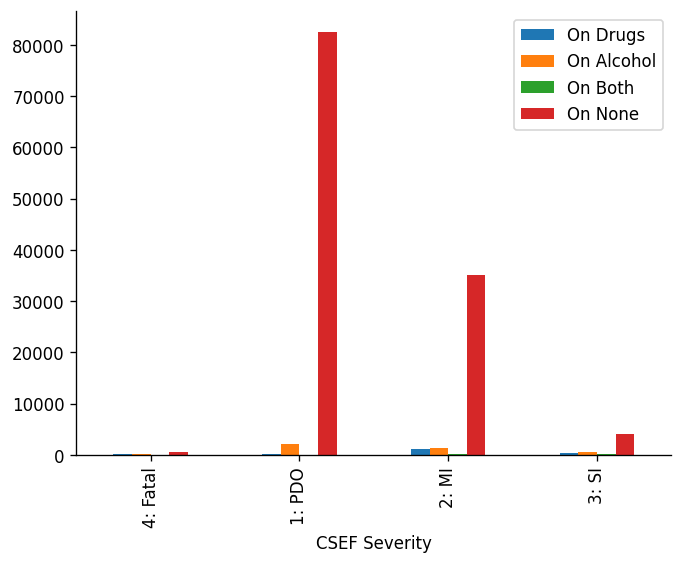

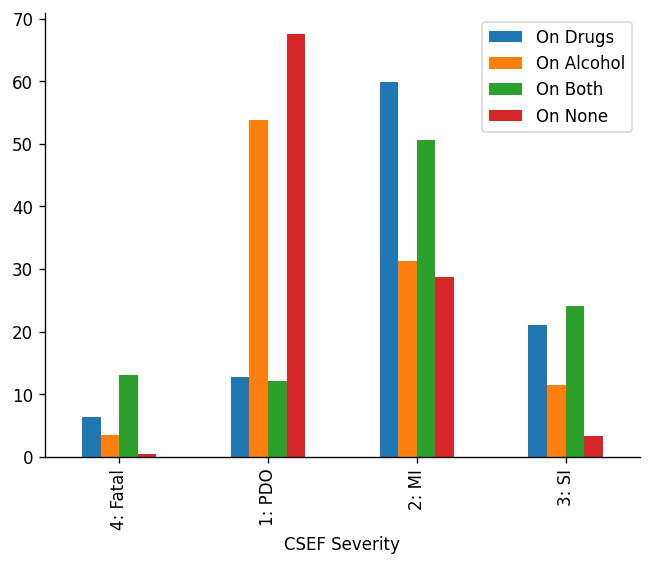

In [ ]:
# Ajout : afficher explicitement les deux figures originales.
plt.show()

### Ajout — Comparaison avec titres et légendes explicites

Les volumes montrent la taille des groupes. Les pourcentages comparent leur composition en gravité. Les deux lectures se complètent, sans démontrer un effet causal.

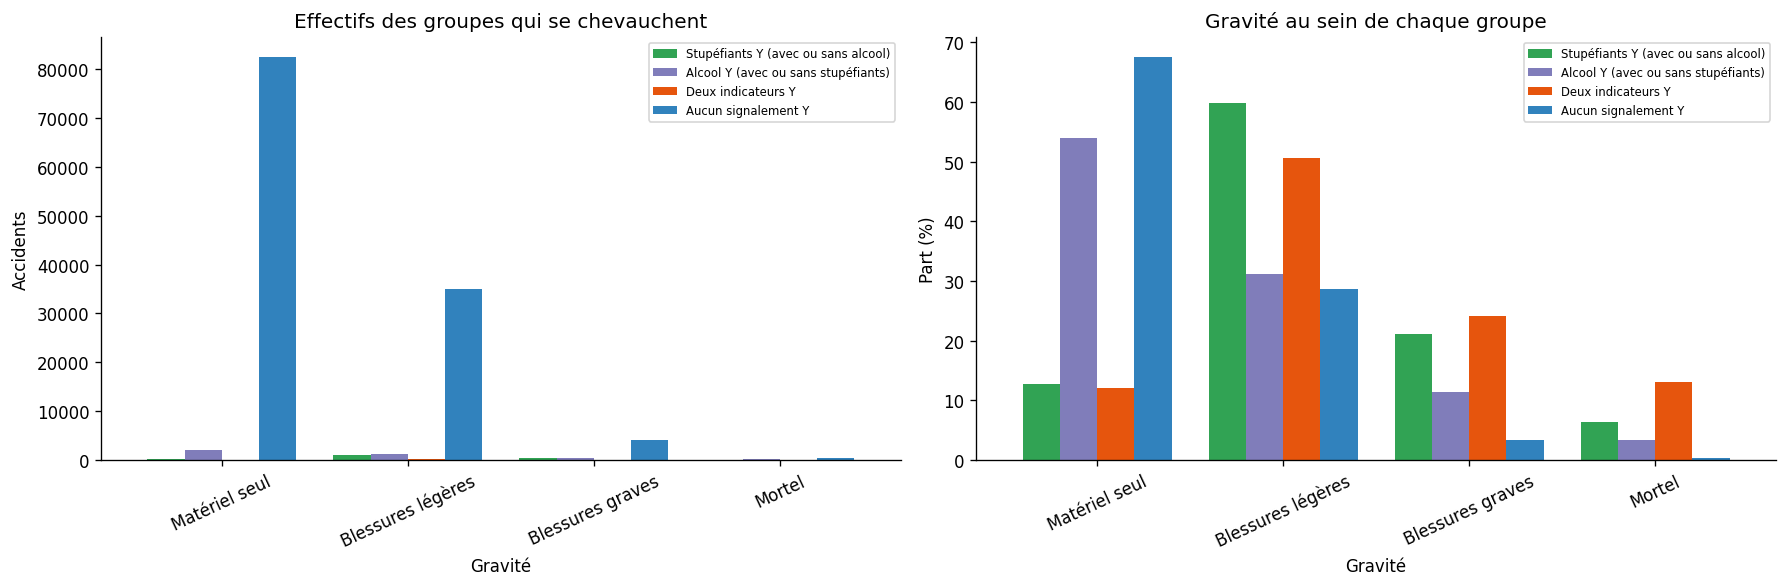

In [ ]:
reference_names = {"On Drugs": "Stupéfiants Y (avec ou sans alcool)",
                   "On Alcohol": "Alcool Y (avec ou sans stupéfiants)",
                   "On Both": "Deux indicateurs Y", "On None": "Aucun signalement Y"}
severity_labels = {"1: PDO": "Matériel seul", "2: MI": "Blessures légères",
                   "3: SI": "Blessures graves", "4: Fatal": "Mortel"}
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for frame, ax, ylabel, title in [(pd_df, axes[0], "Accidents", "Effectifs des groupes qui se chevauchent"),
                                (pd_df_per, axes[1], "Part (%)", "Gravité au sein de chaque groupe")]:
    p = frame.set_index("CSEF Severity").reindex(severity_order).rename(columns=reference_names)
    p.index = [severity_labels[x] for x in p.index]
    p.plot.bar(ax=ax, width=0.8, color=["#31a354", "#807dba", "#e6550d", "#3182bd"])
    ax.set(xlabel="Gravité", ylabel=ylabel, title=title)
    ax.tick_params(axis="x", rotation=25)
    ax.legend(fontsize=7, title=None)
fig.tight_layout()
fig.savefig(OUT / "02_comparaison_groupes_reference.png", bbox_inches="tight")
plt.show()

### 4.8 Ajout — Quatre groupes exclusifs

On distingue les accidents où seul l'indicateur alcool est Y, seul l'indicateur stupéfiants est Y, les deux, et aucun. « Seul » décrit les champs de l'accident, pas les résultats de tests de chaque personne. Ces groupes peuvent être additionnés et doivent retrouver le nombre total d'accidents.

,groupe,CSEF Severity,count,total_groupe,part_pct
0,Alcool Y sans stupéfiants Y,1: PDO,2108,3681,57.27
1,Alcool Y sans stupéfiants Y,2: MI,1092,3681,29.67
2,Alcool Y sans stupéfiants Y,3: SI,384,3681,10.43
3,Alcool Y sans stupéfiants Y,4: Fatal,97,3681,2.64
4,Aucun signalement Y,1: PDO,82430,122137,67.49
5,Aucun signalement Y,2: MI,35099,122137,28.74
6,Aucun signalement Y,3: SI,4100,122137,3.36
7,Aucun signalement Y,4: Fatal,508,122137,0.42
8,Deux indicateurs Y,1: PDO,36,298,12.08
9,Deux indicateurs Y,2: MI,151,298,50.67


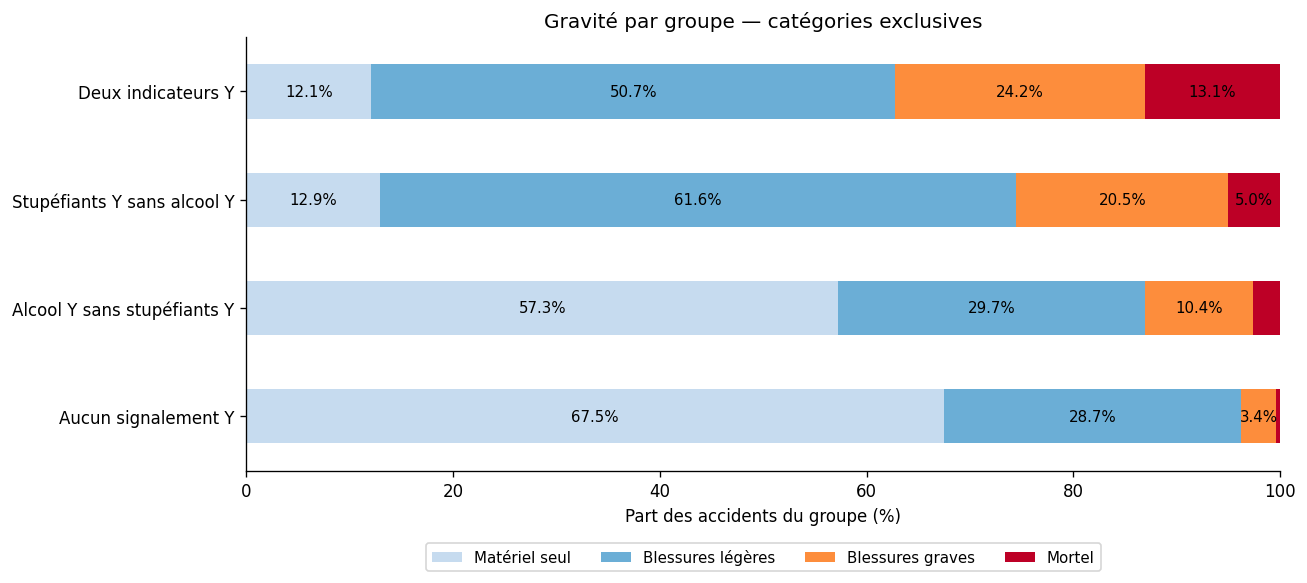

In [ ]:
from pyspark.sql import Window
alcohol_y = F.coalesce(col("DUI Involved") == "Y", F.lit(False))
drugs_y = F.coalesce(col("Drugs Involved") == "Y", F.lit(False))
labeled = crash_df.withColumn("groupe",
    F.when(alcohol_y & drugs_y, "Deux indicateurs Y")
     .when(alcohol_y, "Alcool Y sans stupéfiants Y")
     .when(drugs_y, "Stupéfiants Y sans alcool Y")
     .otherwise("Aucun signalement Y"))
exclusive_labels = ["Aucun signalement Y", "Alcool Y sans stupéfiants Y",
                    "Stupéfiants Y sans alcool Y", "Deux indicateurs Y"]
grid = (spark.createDataFrame([(g,) for g in exclusive_labels], ["groupe"])
    .crossJoin(spark.createDataFrame([(s,) for s in severity_order], ["CSEF Severity"])))
exclusive_stats = (grid.join(labeled.groupBy("groupe", "CSEF Severity").count(),
                            ["groupe", "CSEF Severity"], "left").fillna(0, ["count"])
    .withColumn("total_groupe", F.sum("count").over(Window.partitionBy("groupe")))
    .withColumn("part_pct", F.when(col("total_groupe") > 0, 100 * col("count") / col("total_groupe"))))
exclusive_pd = exclusive_stats.toPandas()
assert int(exclusive_pd["count"].sum()) == n_crash
assert all(abs(x - 100) < 1e-8 for x in exclusive_pd.groupby("groupe")["part_pct"].sum())
display(exclusive_pd.sort_values(["groupe", "CSEF Severity"]).round(2))
table = exclusive_pd.pivot(index="groupe", columns="CSEF Severity", values="part_pct").reindex(index=exclusive_labels, columns=severity_order)
table.columns = [severity_labels[s] for s in table.columns]
fig, ax = plt.subplots(figsize=(11, 5))
table.plot.barh(stacked=True, ax=ax, color=["#c6dbef", "#6baed6", "#fd8d3c", "#bd0026"])
for container in ax.containers:
    ax.bar_label(container, labels=[f"{v:.1f}%" if v >= 3 else "" for v in container.datavalues], label_type="center", fontsize=9)
ax.set(xlim=(0, 100), xlabel="Part des accidents du groupe (%)", ylabel="", title="Gravité par groupe — catégories exclusives")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=4, fontsize=9)
fig.tight_layout()
fig.savefig(OUT / "03_gravite_groupes_exclusifs.png", bbox_inches="tight")
plt.show()

## 5. Comparaison RDD, DataFrame et SQL
### 5.1 Code de l'auteur — Informations sur les unités à Adelaide

Le libellé `année-mois-jour de semaine` ne donne pas le jour du mois : ce n'est pas une date calendaire complète. On conserve les trois cellules d'origine.

**Attention à la version RDD :** après retrait de `REPORT_ID`, certains indices sélectionnent d'autres champs que ceux annoncés. Par exemple, `line[1][0][7]` correspond à l'âge et `line[1][1][6]` au nombre de décès. Une version harmonisée est ajoutée après les trois reproductions pour vérifier une véritable équivalence.

In [ ]:
# RDD Implementation
def parseKey(line):
    lines = line.split(',')
    array_line = []
    for value in lines:
        array_line.append(str(value).replace('"', ''))
    return (array_line[0], array_line[1:] )
units_rdd1 = units_rdd.map(parseKey)
crash_rdd1 = crash_rdd.map(parseKey)
joined_rdd = units_rdd1.join(crash_rdd1)
def parseRecord1(line):
    
    if line[1][1][1] == 'ADELAIDE':
        array_line = []
        array_line.append(line[1][1][1])
        array_line.append(line[1][0][7])
        array_line.append(line[1][0][8])
        array_line.append(line[1][0][11])
        array_line.append(line[1][1][12])
        array_line.append(line[1][1][6])
        array_line.append(line[1][1][9] + "-" + line[1][1][10] + "-" + line[1][1][11])
        return (array_line)
    
pharsed_rdd = joined_rdd.map(parseRecord1)
filtered_pharsed_rdd=pharsed_rdd.filter(lambda x: x is not None)
filtered_pharsed_rdd.collect()

Out[47]: 
[['ADELAIDE', '047', 'SA', 'Unknown', '05:45 pm', '0', '2012-January-Friday'],
 ['ADELAIDE', 'XXX', '', '', '05:45 pm', '0', '2012-January-Friday'],
 ['ADELAIDE',
  '031',
  'SA',
  'Not Towing',
  '05:55 pm',
  '0',
  '2012-February-Wednesday'],
 ['ADELAIDE',
  '062',
  'SA',
  'Not Towing',
  '05:55 pm',
  '0',
  '2012-February-Wednesday'],
 ['ADELAIDE',
  '074',
  'SA',
  'Not Towing',
  '02:40 pm',
  '0',
  '2012-February-Thursday'],
 ['ADELAIDE', '031', '', '', '02:40 pm', '0', '2012-February-Thursday'],
 ['ADELAIDE',
  '031',
  'SA',
  'Unknown',
  '05:28 pm',
  '0',
  '2012-February-Wednesday'],
 ['ADELAIDE', 'XXX', '', '', '05:28 pm', '0', '2012-February-Wednesday'],
 ['ADELAIDE',
  '030',
  'SA',
  'Not Towing',
  '08:15 am',
  '0',
  '2012-February-Thursday'],
 ['ADELAIDE',
  '039',
  'SA',
  'Not Towing',
  '08:15 am',
  '0',
  '2012-February-Thursday'],
 ['ADELAIDE',
  '032',
  'SA',
  'Not Towing',
  '07:05 pm',
  '0',
  '2012-February-Thursday'],
 ['ADELAIDE',
 

In [ ]:
# DataFrame implementation
joined_df = crash_df.join(units_df,crash_df.REPORT_ID==units_df.REPORT_ID, how='inner')
def find_date(d,m,y):
    return y + "-" + m + "-" + d
    
find_date_udf = udf(find_date)
joined_date_df = joined_df.withColumn('Date',find_date_udf('Day', 'Month', 'Year'))
joined_date_df = joined_date_df.filter(col("Suburb") == 'ADELAIDE')
joined_date_df.select('Date', 'Time', 'Total Cas', 'Sex', 'Age', 'Licence Type', 'Suburb').collect()

Out[48]: 
[Row(Date='2012-January-Monday', Time='08:45 am', Total Cas=0, Sex='Male', Age='084', Licence Type='Full', Suburb='ADELAIDE'),
 Row(Date='2012-January-Monday', Time='08:45 am', Total Cas=0, Sex='Male', Age='040', Licence Type='Full', Suburb='ADELAIDE'),
 Row(Date='2012-January-Friday', Time='05:45 pm', Total Cas=0, Sex='Male', Age='047', Licence Type='Full', Suburb='ADELAIDE'),
 Row(Date='2012-January-Friday', Time='05:45 pm', Total Cas=0, Sex='Male', Age='XXX', Licence Type=None, Suburb='ADELAIDE'),
 Row(Date='2012-January-Friday', Time='07:30 pm', Total Cas=1, Sex='Female', Age='018', Licence Type='Provisional 2', Suburb='ADELAIDE'),
 Row(Date='2012-January-Friday', Time='07:30 pm', Total Cas=1, Sex='Male', Age='020', Licence Type='Full', Suburb='ADELAIDE'),
 Row(Date='2012-January-Saturday', Time='08:00 am', Total Cas=0, Sex='Female', Age='024', Licence Type='Provisional 1 ', Suburb='ADELAIDE'),
 Row(Date='2012-January-Saturday', Time='08:00 am', Total Cas=0, Sex='Male', A

In [ ]:
# SparkSQL implementation
units_df.createOrReplaceTempView("units_table")
crash_df.createOrReplaceTempView("crash_table")
joined_table = spark.sql('''
  SELECT (Year || '-' || Month || '-' || Day) as Date, Time, `Total Cas`, Sex, Age, `Licence Type`, Suburb
  FROM units_table u JOIN crash_table c
  ON u.REPORT_ID = c.REPORT_ID
  where c.Suburb == 'ADELAIDE'
''')
joined_table.collect()

Out[49]: 
[Row(Date='2012-January-Monday', Time='08:45 am', Total Cas=0, Sex='Male', Age='084', Licence Type='Full', Suburb='ADELAIDE'),
 Row(Date='2012-January-Monday', Time='08:45 am', Total Cas=0, Sex='Male', Age='040', Licence Type='Full', Suburb='ADELAIDE'),
 Row(Date='2012-January-Friday', Time='05:45 pm', Total Cas=0, Sex='Male', Age='047', Licence Type='Full', Suburb='ADELAIDE'),
 Row(Date='2012-January-Friday', Time='05:45 pm', Total Cas=0, Sex='Male', Age='XXX', Licence Type=None, Suburb='ADELAIDE'),
 Row(Date='2012-January-Friday', Time='07:30 pm', Total Cas=1, Sex='Female', Age='018', Licence Type='Provisional 2', Suburb='ADELAIDE'),
 Row(Date='2012-January-Friday', Time='07:30 pm', Total Cas=1, Sex='Male', Age='020', Licence Type='Full', Suburb='ADELAIDE'),
 Row(Date='2012-January-Saturday', Time='08:00 am', Total Cas=0, Sex='Female', Age='024', Licence Type='Provisional 1 ', Suburb='ADELAIDE'),
 Row(Date='2012-January-Saturday', Time='08:00 am', Total Cas=0, Sex='Male', A

### Correction complémentaire — Sélectionner les mêmes champs dans les trois API

On ajoute aussi l'identifiant de l'unité et ses victimes. `No Of Cas` concerne l'unité ; `Total Cas` concerne l'accident entier et se répète après la jointure. Les trois versions suivent une même sélection et un même traitement des valeurs nulles. On vérifie le contenu avec les multiplicités, pas seulement les effectifs.

In [ ]:
comparison_columns = ["REPORT_ID", "Unit No", "Date", "Time", "victimes_unite",
                      "victimes_accident", "Sex", "Age", "Licence Type", "Suburb"]
adelaide_corrected_df = (crash_df.alias("c").join(units_df.alias("u"), "REPORT_ID")
    .filter(col("c.Suburb") == "ADELAIDE")
    .select(col("REPORT_ID"), col("u.Unit No"),
            F.concat_ws("-", col("c.Year"), col("c.Month"), col("c.Day")).alias("Date"),
            col("c.Time"), col("u.No Of Cas").alias("victimes_unite"),
            col("c.Total Cas").alias("victimes_accident"), col("u.Sex"), col("u.Age"),
            col("u.Licence Type"), col("c.Suburb")))
adelaide_corrected_sql = spark.sql("""
    SELECT c.REPORT_ID, u.`Unit No`, concat_ws('-', c.Year, c.Month, c.Day) AS Date,
           c.Time, u.`No Of Cas` AS victimes_unite, c.`Total Cas` AS victimes_accident,
           u.Sex, u.Age, u.`Licence Type`, c.Suburb
    FROM crash_table c JOIN units_table u ON c.REPORT_ID = u.REPORT_ID
    WHERE c.Suburb = 'ADELAIDE'
""")
c_pairs = crash_df.rdd.map(lambda r: (r.REPORT_ID, r.asDict()))
u_pairs = units_df.rdd.map(lambda r: (r.REPORT_ID, r.asDict()))
def corrected_adelaide_projection(record):
    key, (c, u) = record
    date_label = "-".join(str(c[x]) for x in ["Year", "Month", "Day"] if c[x] is not None)
    return (key, u["Unit No"], date_label, c["Time"], u["No Of Cas"], c["Total Cas"],
            u["Sex"], u["Age"], u["Licence Type"], c["Suburb"])
adelaide_corrected_rdd = (c_pairs.filter(lambda kv: kv[1]["Suburb"] == "ADELAIDE")
    .join(u_pairs).map(corrected_adelaide_projection))
adelaide_rdd_as_df = spark.createDataFrame(adelaide_corrected_rdd, adelaide_corrected_df.schema)
def assert_same_rows(left, right, columns):
    left, right = left.select(columns), right.select(columns)
    assert left.schema == right.schema, "Schémas différents"
    assert left.exceptAll(right).limit(1).count() == 0, "Différence de lignes (gauche)"
    assert right.exceptAll(left).limit(1).count() == 0, "Différence de lignes (droite)"
assert_same_rows(adelaide_corrected_df, adelaide_corrected_sql, comparison_columns)
assert_same_rows(adelaide_corrected_df, adelaide_rdd_as_df, comparison_columns)
print("Sélections harmonisées : égalité RDD / DataFrame / SQL")
adelaide_corrected_df.orderBy("REPORT_ID", "Unit No").show(10, truncate=False)

Sélections harmonisées : égalité RDD / DataFrame / SQL
+---------------------+-------+-------------------+--------+--------------+-----------------+------+---+------------+--------+
|REPORT_ID            |Unit No|Date               |Time    |victimes_unite|victimes_accident|Sex   |Age|Licence Type|Suburb  |
+---------------------+-------+-------------------+--------+--------------+-----------------+------+---+------------+--------+
|2012-10007-21/08/2019|01     |2012-June-Wednesday|05:30 pm|0             |0                |Female|036|Unknown     |ADELAIDE|
|2012-10007-21/08/2019|02     |2012-June-Wednesday|05:30 pm|0             |0                |Male  |XXX|Unknown     |ADELAIDE|
|2012-10027-21/08/2019|01     |2012-June-Thursday |02:45 pm|0             |0                |Male  |062|Full        |ADELAIDE|
|2012-10027-21/08/2019|02     |2012-June-Thursday |02:45 pm|0             |0                |Female|020|Full        |ADELAIDE|
|2012-10040-21/08/2019|01     |2012-June-Thursday |05:24

### 5.2 Code de l'auteur — Dernière requête sur les permis

Le titre du sujet annonce les victimes d'accidents avec un conducteur sans permis. **Les trois cellules ci-dessous ne répondent pas exactement à cette question et ne sont pas équivalentes :**

| Version reproduite | Ce qu'elle calcule effectivement |
|---|---|
| RDD | Somme du total des victimes de l'accident sur les lignes jointes, avec des filtres de codes de permis ; les chaînes vides ne sont pas des `None`. |
| DataFrame | Nombre de lignes où `No Of Cas` est non nul après des filtres de permis renseignés. |
| SQL | Nombre de lignes où `Total Cas` est non nul après des filtres de permis renseignés. |

Aucune des trois n'impose ici `Licence Type == 'Unlicenced'`. On conserve les cellules pour reproduire fidèlement le sujet, puis on écrit la même question métier avec les trois API.

In [ ]:
# RDD implementation
def parseKey(line):
    lines = line.split(',')
    array_line = []
    for value in lines:
        array_line.append(str(value).replace('"', ''))
    return (array_line[0], array_line[1:] )
units_rdd1 = units_rdd.map(parseKey)
crash_rdd1 = crash_rdd.map(parseKey)
joined_rdd = units_rdd1.join(crash_rdd1)
def parseRecord2(line):
    return (line[1][1][1], int(line[1][1][5]))
    
filtered_rdd = joined_rdd.filter(lambda x: (x[1][0][9] != "XX") & (x[1][0][8] != "UNKNOWN") & (x[1][0][10] != "Unknown") & (x[1][0][9] is not None) & (x[1][0][10] is not None) & (x[1][0][11] is not None))
pharased_filtered_rdd = filtered_rdd.map(parseRecord2)
result= pharased_filtered_rdd.groupByKey().mapValues(lambda x: sum(x))
result.collect()

Out[51]: 
[('MELROSE PARK', 242),
 ('SALISBURY SOUTH', 170),
 ('REGENCY PARK', 320),
 ('HILLCREST', 104),
 ('POORAKA', 832),
 ('MANNINGHAM', 241),
 ('PAYNEHAM', 2080),
 ('GAWLER EAST', 82),
 ('KINGSWOOD', 322),
 ('BEVERLEY', 214),
 ('GOODWOOD', 111),
 ('PARAFIELD GARDENS', 623),
 ...]


In [ ]:
# DataFrame implementation
joined_df = crash_df.join(units_df,crash_df.REPORT_ID==units_df.REPORT_ID, how='inner')
without_lic_df = joined_df.dropna(subset=('Licence Type','Licence Class', 'Lic State'), how='all')
by_suburb_no_lic_no_df = without_lic_df.filter((col('Licence Type') != 'Unknown') &(col('Licence Class') != 'XX') &(col('Lic State') != 'UNKNOWN')).groupby('Suburb').agg(F.count('No Of Cas').alias('Total casualty'))
by_suburb_no_lic_no_df.collect()

Out[52]: 
[Row(Suburb='PANORAMA', Total casualty=262),
 Row(Suburb='SEATON', Total casualty=952),
 Row(Suburb='MITCHELL PARK', Total casualty=879),
 Row(Suburb='THEBARTON', Total casualty=733),
 Row(Suburb='SURREY DOWNS', Total casualty=191),
 Row(Suburb='NEWTON', Total casualty=421),
 Row(Suburb='HACKNEY', Total casualty=509),
 Row(Suburb='FLINDERS PARK', Total casualty=620),
 Row(Suburb='ST GEORGES', Total casualty=160),
 Row(Suburb='WOODVILLE PARK', Total casualty=515),
 Row(Suburb='MITCHAM', Total casualty=153),
 Row(Suburb='LOCKLEYS', Total casualty=550),
 ...]


In [ ]:
# SparkSQL implementation
units_df.createOrReplaceTempView("units_table")
crash_df.createOrReplaceTempView("crash_table")
joined_table = spark.sql('''
  SELECT Suburb, COUNT(`Total Cas`)
  FROM units_table u JOIN crash_table c
  ON u.REPORT_ID = c.REPORT_ID
  WHERE `Lic State` IS NOT NULL and `Licence Class` IS NOT NULL and `Licence Type` IS NOT NULL and
  `Licence Type` != 'Unknown' and
  `Licence Class` != 'XX' and
  `Lic State` != 'UNKNOWN'
GROUP BY Suburb
''')
joined_table.collect()

Out[53]: 
[Row(Suburb='PANORAMA', count(Total Cas)=262),
 Row(Suburb='SEATON', count(Total Cas)=952),
 Row(Suburb='MITCHELL PARK', count(Total Cas)=879),
 Row(Suburb='THEBARTON', count(Total Cas)=733),
 Row(Suburb='SURREY DOWNS', count(Total Cas)=191),
 Row(Suburb='NEWTON', count(Total Cas)=421),
 Row(Suburb='HACKNEY', count(Total Cas)=509),
 Row(Suburb='FLINDERS PARK', count(Total Cas)=620),
 Row(Suburb='ST GEORGES', count(Total Cas)=160),
 Row(Suburb='WOODVILLE PARK', count(Total Cas)=515),
 Row(Suburb='MITCHAM', count(Total Cas)=153),
 Row(Suburb='LOCKLEYS', count(Total Cas)=550),
 ...]


### Correction complémentaire — Accidents avec au moins une unité sans permis

La définition retenue est celle de la section 3.6. On déduplique les identifiants avec les RDD, on utilise un `left_semi` en DataFrame et un `EXISTS` en SQL. Chaque accident contribue une seule fois à la somme de ses victimes.

In [ ]:
unlicensed_corrected_sql = spark.sql("""
    SELECT c.Suburb, COUNT(*) AS accidents, SUM(c.`Total Cas`) AS victimes
    FROM crash_table c
    WHERE EXISTS (SELECT 1 FROM units_table u
                  WHERE u.REPORT_ID = c.REPORT_ID AND u.`Licence Type` = 'Unlicenced')
    GROUP BY c.Suburb
""")
unlicensed_keys_rdd = (units_df.rdd.filter(lambda r: r["Licence Type"] == "Unlicenced")
    .map(lambda r: (r.REPORT_ID, 1)).reduceByKey(lambda a, b: 1))
unlicensed_result_rdd = (c_pairs.join(unlicensed_keys_rdd)
    .map(lambda kv: (kv[1][0]["Suburb"], (1, kv[1][0]["Total Cas"])))
    .reduceByKey(lambda a, b: (a[0] + b[0], a[1] + b[1]))
    .map(lambda kv: (kv[0], kv[1][0], kv[1][1])))
unlicensed_corrected_rdd_df = spark.createDataFrame(unlicensed_result_rdd, unlicensed_corrected.schema)
cols = ["Suburb", "accidents", "victimes"]
assert_same_rows(unlicensed_corrected, unlicensed_corrected_sql, cols)
assert_same_rows(unlicensed_corrected, unlicensed_corrected_rdd_df, cols)
print("Question sans permis harmonisée : égalité RDD / DataFrame / SQL")
unlicensed_corrected_sql.orderBy(F.desc("victimes"), "Suburb").show(10, truncate=False)

Question sans permis harmonisée : égalité RDD / DataFrame / SQL
+--------------+---------+--------+
|Suburb        |accidents|victimes|
+--------------+---------+--------+
|ADELAIDE      |149      |42      |
|SALISBURY     |40       |30      |
|PROSPECT      |48       |27      |
|INGLE FARM    |32       |22      |
|MORPHETT VALE |49       |20      |
|DRY CREEK     |19       |19      |
|MURRAY BRIDGE |30       |19      |
|SALISBURY EAST|30       |19      |
|MAWSON LAKES  |36       |17      |
|NORTH ADELAIDE|42       |17      |
+--------------+---------+--------+
only showing top 10 rows



## 6. Ajouts — Cohérence des victimes et évolution temporelle

On crée une copie typée pour les contrôles et graphiques, sans modifier les tables de l'auteur. Une somme au niveau accident doit rester sur une table ayant une ligne par accident. On vérifie aussi la période et l'identité : total des victimes = décès + blessures graves + blessures légères.

In [ ]:
crash_typed = crash_df
for name in ["Year", "Total Cas", "Total Fats", "Total SI", "Total MI"]:
    crash_typed = crash_typed.withColumn(name, col(name).cast("int"))
years = sorted(r[0] for r in crash_typed.select("Year").distinct().collect())
assert years == list(range(2012, 2020))
required = ["Total Cas", "Total Fats", "Total SI", "Total MI"]
assert crash_typed.filter(reduce(lambda a, b: a | b, [col(c).isNull() for c in required])).count() == 0
assert crash_typed.filter(col("Total Cas") != col("Total Fats") + col("Total SI") + col("Total MI")).count() == 0
summary = crash_typed.agg(F.count("*").alias("accidents"), F.sum("Total Cas").alias("victimes"),
    F.sum("Total Fats").alias("deces"), F.sum("Total SI").alias("blesses_graves"),
    F.sum("Total MI").alias("blesses_legers")).first().asDict()
display(pd.DataFrame([summary]))
print("Période et identité des victimes : vérifiées")

Période et identité des victimes : vérifiées


,accidents,victimes,deces,blesses_graves,blesses_legers
0,127672,53255,781,5744,46730


### 6.1 Évolution annuelle

Le nombre d'accidents enregistrés et la part d'accidents graves ou mortels décrivent deux dimensions différentes. Sans données de trafic ni analyse des règles de déclaration, une baisse du nombre d'accidents ne démontre pas à elle seule une réduction du risque par trajet.

,Year,accidents,victimes,deces,graves_ou_mortels,part_graves_ou_mortels_pct
0,2012,22829,7479,94,723,3.17
1,2013,16675,7177,97,755,4.53
2,2014,16162,6982,108,690,4.27
3,2015,15431,6660,102,753,4.88
4,2016,16775,6565,86,651,3.88
5,2017,13237,6237,100,626,4.73
6,2018,13599,6124,80,560,4.12
7,2019,12964,6031,114,839,6.47


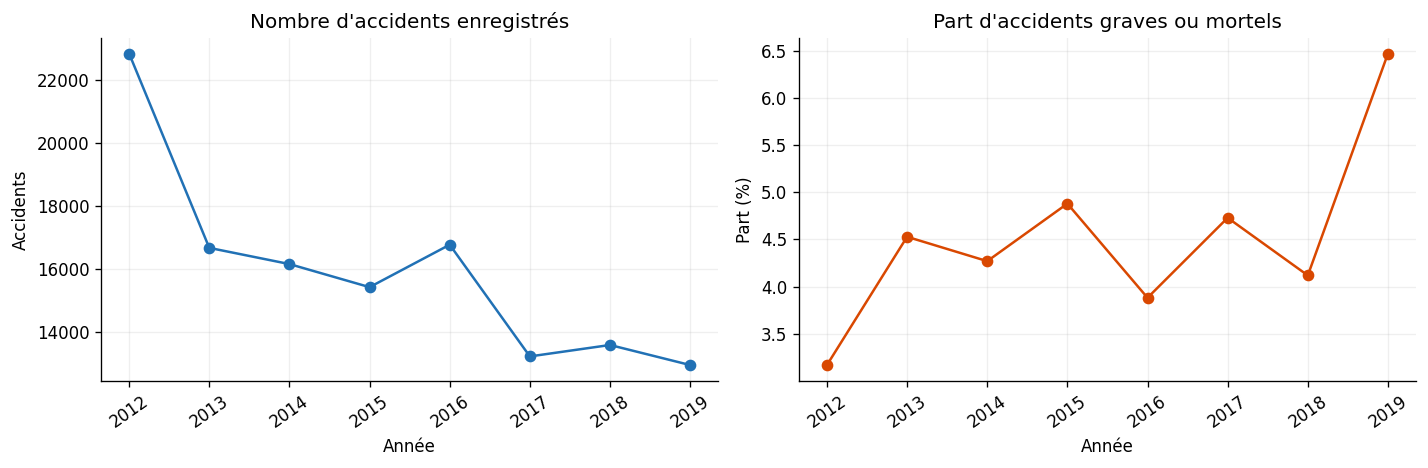

In [ ]:
annual = (crash_typed.groupBy("Year").agg(F.count("*").alias("accidents"),
    F.sum("Total Cas").alias("victimes"), F.sum("Total Fats").alias("deces"),
    F.sum(col("CSEF Severity").isin("3: SI", "4: Fatal").cast("int")).alias("graves_ou_mortels"))
    .withColumn("part_graves_ou_mortels_pct", 100 * col("graves_ou_mortels") / col("accidents"))
    .orderBy("Year"))
annual_pd = annual.toPandas()
display(annual_pd.round(2))
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(annual_pd["Year"], annual_pd["accidents"], marker="o", color="#2171b5")
axes[0].set(title="Nombre d'accidents enregistrés", xlabel="Année", ylabel="Accidents")
axes[1].plot(annual_pd["Year"], annual_pd["part_graves_ou_mortels_pct"], marker="o", color="#d94801")
axes[1].set(title="Part d'accidents graves ou mortels", xlabel="Année", ylabel="Part (%)")
for ax in axes:
    ax.set_xticks(annual_pd["Year"])
    ax.tick_params(axis="x", rotation=35)
    ax.grid(alpha=0.2)
fig.tight_layout()
fig.savefig(OUT / "04_evolution_annuelle.png", bbox_inches="tight")
plt.show()

### 6.2 Répartition selon le jour de semaine

La colonne `Day` donne le jour de semaine. Ce graphique montre les volumes enregistrés, sans corriger les différences de trafic entre les jours.

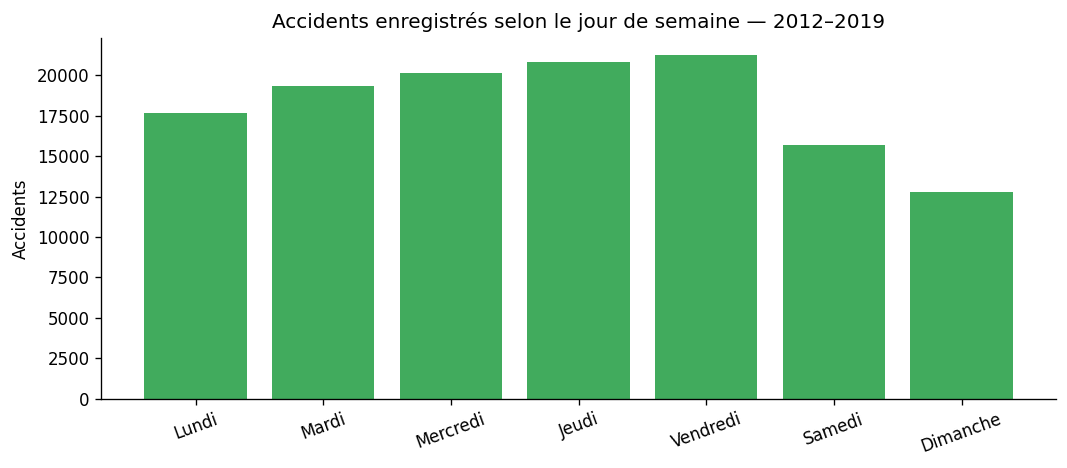

In [ ]:
week_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
week_labels = ["Lundi", "Mardi", "Mercredi", "Jeudi", "Vendredi", "Samedi", "Dimanche"]
weekday_pd = crash_df.groupBy("Day").count().toPandas().set_index("Day").reindex(week_order)
assert weekday_pd["count"].sum() == n_crash
fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(week_labels, weekday_pd["count"], color="#41ab5d")
ax.set(title="Accidents enregistrés selon le jour de semaine — 2012–2019", ylabel="Accidents")
ax.tick_params(axis="x", rotation=20)
fig.tight_layout()
fig.savefig(OUT / "05_jour_semaine.png", bbox_inches="tight")
plt.show()

## 7. Exécution Spark et limites du périmètre

Une agrégation peut comporter une lecture, une agrégation partielle, un échange entre partitions (*shuffle*) et une agrégation finale. Les DataFrames et SQL utilisent le même moteur d'optimisation. Les RDD conservent davantage de logique explicite en Python.

Le volume de ce jeu reste traitable sur une machine. L'intérêt « Big Data » est méthodologique : lire plusieurs fichiers, partitionner, joindre et agréger. Cette étude ne mesure pas les performances d'un cluster et ne prouve pas que Spark serait plus rapide que pandas.

Les appels `collect()` de l'auteur sont conservés. Ils doivent être remplacés ou limités pour des volumes beaucoup plus importants. Les graphiques complémentaires ne convertissent en pandas que des agrégats de petite taille.

In [ ]:
# Ajout : lire le plan physique d'une agrégation.
fatalities_by_type.explain(mode="formatted")

== Physical Plan ==
AdaptiveSparkPlan (16)
+- == Final Plan ==
   * Sort (10)
   +- AQEShuffleRead (9)
      +- ShuffleQueryStage (8), Statistics(sizeInBytes=528.0 B, rowCount=13)
         +- Exchange (7)
            +- * HashAggregate (6)
               +- AQEShuffleRead (5)
                  +- ShuffleQueryStage (4), Statistics(sizeInBytes=2.1 KiB, rowCount=52)
                     +- Exchange (3)
                        +- * HashAggregate (2)
                           +- Scan csv  (1)
+- == Initial Plan ==
   Sort (15)
   +- Exchange (14)
      +- HashAggregate (13)
         +- Exchange (12)
            +- HashAggregate (11)
               +- Scan csv  (1)


(1) Scan csv 
Output [2]: [Total Fats#96, Crash Type#112]
Batched: false
Location: InMemoryFileIndex [file:/workspace/scratch/3668ae3497ec/crash_data/2012_DATA_SA_Crash.csv, ... 7 entries]
ReadSchema: struct<Total Fats:string,Crash Type:string>

(2) HashAggregate [codegen id : 1]
Input [2]: [Total Fats#96, Crash Type#112]
Keys 

## 8. Conclusion calculée et discussion

La synthèse suivante reprend les résultats de cette exécution. Elle distingue les reproductions des corrections et ne déduit pas de causalité à partir de statistiques descriptives. Avant le rendu, compléter cette lecture avec votre propre interprétation des graphiques.

In [ ]:
serious_pd = (exclusive_pd[exclusive_pd["CSEF Severity"].isin(["3: SI", "4: Fatal"])]
    .groupby("groupe").agg(graves_ou_mortels=("count", "sum"), total=("total_groupe", "first")))
serious_pd["part_pct"] = 100 * serious_pd["graves_ou_mortels"] / serious_pd["total"]
group_lines = "\n".join(f"- **{name}** : {int(row.total):,} accidents, dont {row.part_pct:.2f} % graves ou mortels."
    for name, row in serious_pd.sort_values("part_pct", ascending=False).iterrows())
top_type = fatalities_by_type.first()
change = 100 * (annual_pd.iloc[-1]["accidents"] / annual_pd.iloc[0]["accidents"] - 1)
conclusion = f"""### Synthèse de l'exécution

Le jeu contient **{summary['accidents']:,} accidents**, **{n_units:,} unités** et
**{summary['victimes']:,} victimes**, dont **{summary['deces']:,} décès**.
Le type comptant le plus de décès est **{top_type['Crash Type']}** ({int(top_type['Total fatalities'])} décès).
Ces volumes ne mesurent pas un risque par kilomètre parcouru.

Les quatre groupes exclusifs donnent :
{group_lines}

Entre 2012 et 2019, le nombre d'accidents enregistrés varie de **{change:+.2f} %**,
sans ajustement selon l'exposition au trafic.

La somme reproduite pour les accidents avec une unité sans permis est **{original_total:,} victimes**
après jointure, contre **{corrected_total:,}** en comptant chaque accident une seule fois.
Les versions **corrigées et harmonisées** des deux questions donnent les mêmes lignes
avec RDD, DataFrame et SQL. Les cellules originales sont conservées et leurs limites sont discutées.

### Limites et prolongements

- Un champ vide ne prouve pas un test négatif ; les deux indicateurs Y peuvent concerner des personnes différentes.
- Les données ne décrivent pas les trajets sans accident : aucun risque par trajet ne peut être estimé directement.
- La collecte, les règles de déclaration, l'âge, les lieux et les horaires peuvent influer sur les associations observées.
- Les années de véhicules et âges atypiques méritent une investigation avant une analyse explicative.
- Une suite pertinente serait l'ajout de données de trafic et une analyse multivariée avec validation séparée.
"""
display(Markdown(conclusion))

### Synthèse de l'exécution

Le jeu contient **127,672 accidents**, **272,591 unités** et
**53,255 victimes**, dont **781 décès**.
Le type comptant le plus de décès est **Hit Fixed Object** (245 décès).
Ces volumes ne mesurent pas un risque par kilomètre parcouru.

Les quatre groupes exclusifs donnent :
- **Deux indicateurs Y** : 298 accidents, dont 37.25 % graves ou mortels.
- **Stupéfiants Y sans alcool Y** : 1,556 accidents, dont 25.51 % graves ou mortels.
- **Alcool Y sans stupéfiants Y** : 3,681 accidents, dont 13.07 % graves ou mortels.
- **Aucun signalement Y** : 122,137 accidents, dont 3.77 % graves ou mortels.

Entre 2012 et 2019, le nombre d'accidents enregistrés varie de **-43.21 %**,
sans ajustement selon l'exposition au trafic.

La somme reproduite pour les accidents avec une unité sans permis est **2,072 victimes**
après jointure, contre **2,053** en comptant chaque accident une seule fois.
Les versions **corrigées et harmonisées** des deux questions donnent les mêmes lignes
avec RDD, DataFrame et SQL. Les cellules originales sont conservées et leurs limites sont discutées.

### Limites et prolongements

- Un champ vide ne prouve pas un test négatif ; les deux indicateurs Y peuvent concerner des personnes différentes.
- Les données ne décrivent pas les trajets sans accident : aucun risque par trajet ne peut être estimé directement.
- La collecte, les règles de déclaration, l'âge, les lieux et les horaires peuvent influer sur les associations observées.
- Les années de véhicules et âges atypiques méritent une investigation avant une analyse explicative.
- Une suite pertinente serait l'ajout de données de trafic et une analyse multivariée avec validation séparée.


## 9. Exports et rendu GitHub

Les tableaux exportés sont des agrégats. Les copies typées sont aussi sauvegardées en Parquet, format qui conserve les types ; une sortie Parquet Spark est un dossier de fichiers. Les données originales restent inchangées.

Avant le dépôt : renseigner votre nom, relire les sorties, expliquer les corrections avec vos propres mots, puis sauvegarder ce notebook avec les sorties affichées. Ajouter le notebook et éventuellement ses figures à votre dépôt. Pour un dépôt léger, exclure `source_originale/`, `crash_data/`, `units_data/`, les dossiers Parquet et `.ipynb_checkpoints/` du suivi Git. Le code de téléchargement permet de recréer les entrées.

In [ ]:
pd.DataFrame(manifest).to_csv(OUT / "manifest_sources.csv", index=False)
quality_pd.to_csv(OUT / "qualite_donnees.csv", index=False)
fatalities_type_pd.to_csv(OUT / "deces_par_type.csv", index=False)
pd_df.to_csv(OUT / "gravite_effectifs_auteur.csv", index=False)
pd_df_per.to_csv(OUT / "gravite_pourcentages_auteur.csv", index=False)
exclusive_pd.to_csv(OUT / "gravite_groupes_exclusifs.csv", index=False)
annual_pd.to_csv(OUT / "bilan_annuel.csv", index=False)
unlicensed_corrected.toPandas().to_csv(OUT / "sans_permis_par_localite_corrige.csv", index=False)
(OUT / "conclusion.md").write_text(conclusion, encoding="utf-8")
crash_typed.write.mode("overwrite").parquet(str((OUT / "accidents_parquet").resolve()))
units_df.write.mode("overwrite").parquet(str((OUT / "unites_parquet").resolve()))
run_info = {"execution_utc": datetime.now(timezone.utc).isoformat(), "python": sys.version.split()[0],
    "java": sc._jvm.java.lang.System.getProperty("java.version"), "spark": spark.version,
    "pandas": pd.__version__, "master": sc.master, "source_commit": source_revision,
    "accidents": n_crash, "unites": n_units,
    "controles": "CSV, cles, relation, victimes, pourcentages et equivalence des versions harmonisees"}
(OUT / "environnement.json").write_text(json.dumps(run_info, indent=2, ensure_ascii=False), encoding="utf-8")
print("Exports créés dans :", OUT.resolve())

Exports créés dans : /workspace/scratch/3668ae3497ec/resultats_road_crash


## 10. Bilan : fidélité au sujet et valeur ajoutée

| Élément | Traitement dans ce notebook |
|---|---|
| Cellules de l'auteur | Conservées, avec les mêmes variables et dans le même ordre |
| Exemple `bank.csv` | Reproduit en texte ; fichier absent du sujet, donc exemple non exécuté |
| Configuration locale | Réglages additionnels placés avant la création de session |
| Lecture RDD par `split(',')` | Conservée, puis contrôlée par rapport à un parseur CSV |
| Groupes alcool / stupéfiants | Code conservé, terminologie d'interprétation précisée |
| UDF de pourcentages | Code conservé ; résultats contrôlés à partir des effectifs par une formule indépendante |
| Victimes après jointure | Reproduction suivie d'une correction sans multiplication des accidents |
| Indices RDD et dernière comparaison | Originaux conservés, versions harmonisées ajoutées et vérifiées |
| Explications, qualité et figures | Commentaires français, contrôles et visualisations supplémentaires |

### Références

- [Article de Rakesh Nain](https://medium.com/rakesh-nain/big-data-analysis-of-road-crash-data-using-pyspark-with-pyspark-tutorial-c78ff2c35588).
- [Code et données au commit utilisé](https://github.com/RakeshNain/Big-data-Analysis-of-Road-Crash-Data-using-PySpark-with-PySpark-Tutorial/tree/dab8e6466747903bf1e5bd21ce63fea31bfb6dcc).
- Métadonnées : `source_originale/metadata-for-road-crash.pdf`.
- [Documentation Apache Spark 3.5.6 : CSV](https://spark.apache.org/docs/3.5.6/sql-data-sources-csv.html), [RDD](https://spark.apache.org/docs/3.5.6/rdd-programming-guide.html), [installation](https://spark.apache.org/docs/3.5.6/api/python/getting_started/install.html).

**Attribution :** cellules originales de Rakesh Nain ; commentaires, vérifications et extensions ajoutés dans cette réalisation. Les sorties sont recalculées, sans recopier les tableaux attendus de l'article.

In [ ]:
spark.stop()
print("Session Spark arrêtée. Relancer depuis la création de session pour refaire les analyses.")

Session Spark arrêtée. Relancer depuis la création de session pour refaire les analyses.
